# Eigenfaces with PCA

PCA on 400 face photos: compress each 64×64 image to 20 numbers, then rebuild it.

## Data

400 grayscale faces (40 people, 10 photos each), 64×64 pixels. Each row is one face.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces

data = fetch_olivetti_faces(shuffle=False)
faces = pd.DataFrame(data.data)
faces['target'] = data.target
print(faces.shape)

(400, 4097)


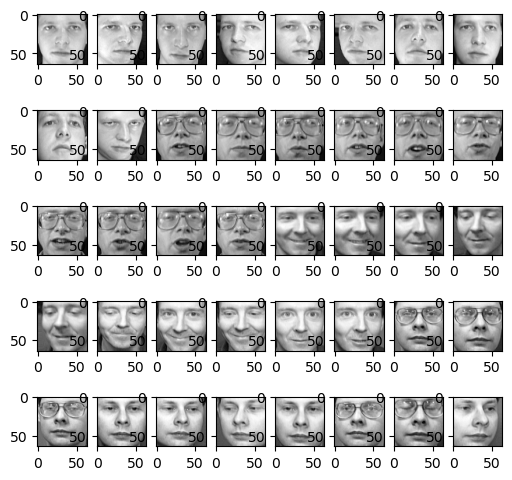

In [2]:
def plot_faces(pixels, nRows,nCols):
    fig, axes = plt.subplots(nRows, nCols, figsize=(6, 6))
    for i, ax in enumerate(axes.flat):
        ax.imshow(np.array(pixels)[i].reshape(64, 64), cmap='gray')
    plt.show()

# Prepare the data
X = faces.drop('target', axis=1)
y = faces['target']

# display the first nRows*nCols of faces in the dataset
plot_faces(X, 5, 8)

## Mean face

(4096,)


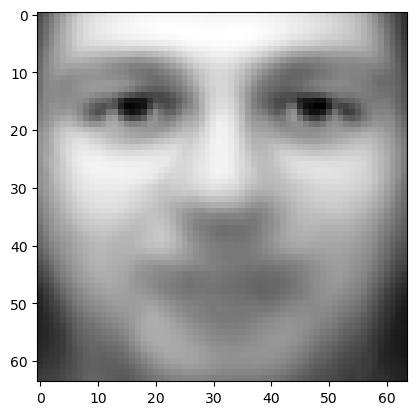

In [3]:
mean_X = X.mean(axis=0)
print(mean_X.shape)
faceplot = plt.imshow(np.array(mean_X).reshape(64, 64), cmap='gray')

## Center the data

Subtract the mean face so only what differs between faces is left.

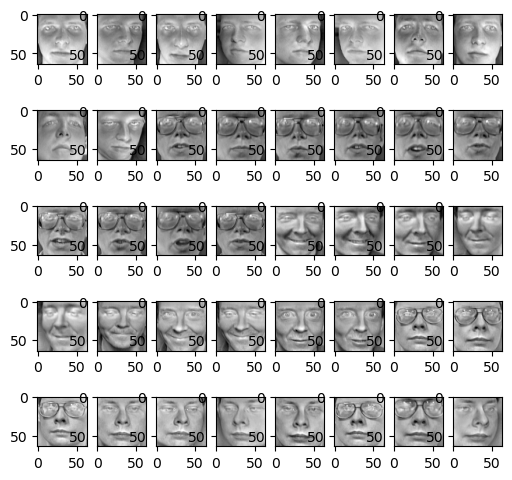

In [4]:
zeromean_X = X - mean_X
plot_faces(zeromean_X, 5, 8)

## PCA: 4,096 pixels to 20 numbers

In [5]:
from sklearn.decomposition import PCA

# reduce to 20 dimensional weight vector to represent each face; dimension reduction from 4096 to 20; input to PCA is centered but not scaled
pca = PCA(n_components=20, random_state=0)
pca.fit(zeromean_X)
print(f'Variance explained: {pca.explained_variance_ratio_.sum():.1%}')

Variance explained: 76.3%


## Eigenfaces

The principal components, drawn as images.

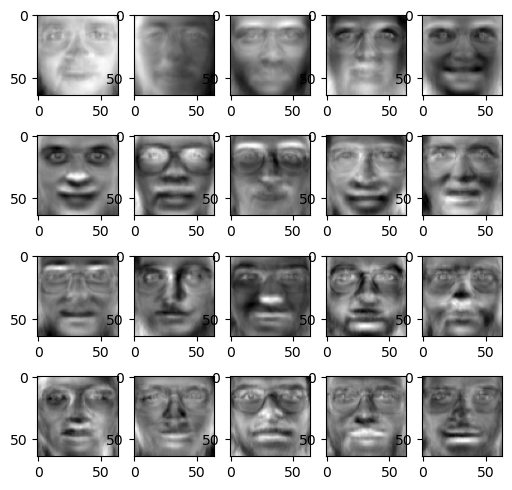

In [6]:
eigenfaces = pca.components_
plot_faces(eigenfaces, 4, 5)

## Reconstruct

Weights times eigenfaces, plus the mean face.

(400, 20)
(20, 4096)
(400, 20)


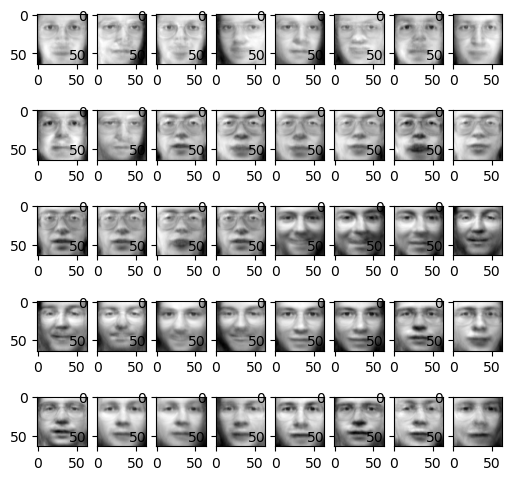

In [7]:
zeromean_X_pca = pca.transform(zeromean_X)
print(zeromean_X_pca.shape)

print(eigenfaces.shape)
print(zeromean_X_pca.shape)

reconstructed_zeromean_X = np.matmul(zeromean_X_pca, eigenfaces)
mean_matrix = np.tile(mean_X, (400,1))
reconstructed_X = reconstructed_zeromean_X + mean_matrix
plot_faces(reconstructed_X, 5, 8)

## Reconstruction error

The difference between original and reconstruction, and the largest L2 error with 20 and with 150 components.

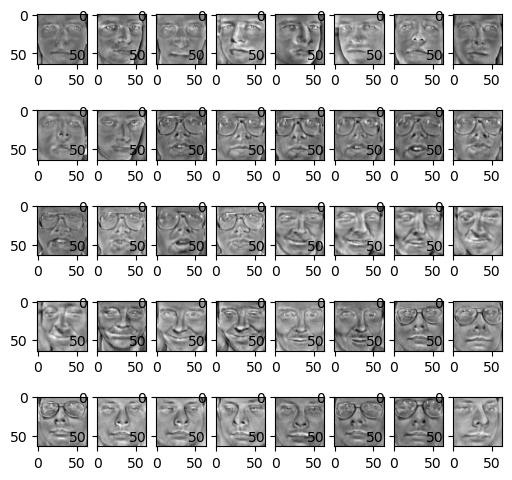

6.2545085


Maximum L2-norm of differences (150 components): 2.135236


In [8]:
diff = X - reconstructed_X
plot_faces(diff, 5, 8)

diff_norm = np.linalg.norm(diff, axis=1)
print(np.max(diff_norm))

pca_150 = PCA(n_components=150, random_state=0)
pca_150.fit(zeromean_X)
zeromean_X_pca_150 = pca_150.transform(zeromean_X)

reconstructed_zeromean_X_150 = pca_150.inverse_transform(zeromean_X_pca_150)
reconstructed_X_150 = reconstructed_zeromean_X_150 + mean_matrix
diff_150 = X - reconstructed_X_150
diff_norm_150 = np.linalg.norm(diff_150, axis=1)
print("Maximum L2-norm of differences (150 components):", np.max(diff_norm_150))

## Walking along an eigenface

From the mean face, two steps down to two steps up one eigenface.

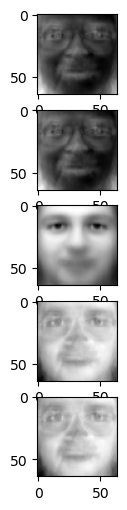

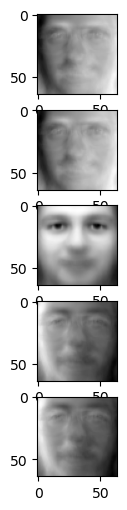

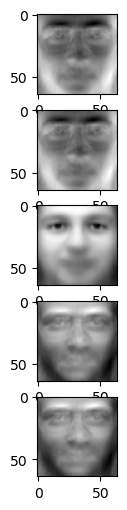

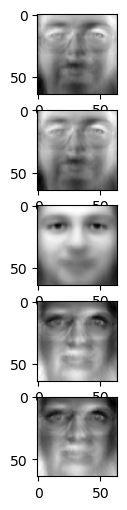

In [9]:
def visualize_eigenface_direction(eigenface_ID):
    face = eigenfaces[eigenface_ID]
    s = pca.singular_values_[eigenface_ID]
    s_row = np.ones(4096) * s

    f0 = np.array(mean_X) - np.array(face) * np.array(2 * s_row)
    f1 = np.array(mean_X) - np.array(face) * np.array(s_row)
    f2 = np.array(mean_X)
    f3 = np.array(mean_X) + np.array(face) * np.array(s_row)
    f4 = np.array(mean_X) + np.array(face) * np.array(2 * s_row)

    f = np.vstack((f0.T, f1.T, f2.T, f3.T, f4.T))
    plot_faces(f, 5, 1)

# Visualize variations along the first four eigenfaces
visualize_eigenface_direction(0)
visualize_eigenface_direction(1)
visualize_eigenface_direction(2)
visualize_eigenface_direction(3)